# Arbitrage statistique : trader l'écart entre deux actions cointégrées
**William Caron-Bastarache** — Case study 2, PolyFinances (sélection RITC)

## Résumé

**Question :** parmi neuf actions (2015–2024), existe-t-il une paire dont l'écart de prix revient vers un niveau stable, et peut-on en tirer une stratégie rentable ?

**Réponse : oui, DDD et HHH.** Les règles ont été fixées avec les données de 2015 à 2019 seulement, puis testées une seule fois sur 2020 à 2024. Sur cette période, elles transforment 100 000 \$ en **126 597 \$**.

| Stratégie DDD–HHH | 2015–2019 (période de construction) | **2020–2024 (test hors échantillon)** | Marché, 2020–2024 (référence) |
|---|---|---|---|
| Rendement total | +40,6 % | **+26,6 %** | +99,1 % |
| Rendement annualisé | +7,1 % | **+4,8 %** | +14,8 % |
| Volatilité annualisée | 4,5 % | **3,7 %** | 12,5 % |
| Ratio de Sharpe | 1,54 | **1,28** | 1,16 |
| Perte maximale (drawdown) | −4,2 % | **−5,9 %** | −17,9 % |
| Trades (gagnants) | 10 (10) | **8 (7)** | — |

*Marché : portefeuille équipondéré des neuf actions. Mesures de risque complètes à la section 6.*

**Ce qu'il faut retenir :**
1. **Une seule paire est vraiment cointégrée.** Sur 36 paires testées, DDD–HHH a une p-value inférieure à 10⁻⁵. La deuxième, BBB–CCC (p = 0,03), ne survit pas à une correction pour tests multiples : avec 36 tests, on s'attend à environ 2 faux positifs au seuil de 5 %. Sur 2020–2024, BBB–CCC n'est d'ailleurs plus cointégrée, alors que DDD–HHH l'est toujours (section 6.2).
2. **La relation est stable.** Le ratio de couverture estimé sur 2015–2019 (0,791) est presque identique à celui qu'on obtient sur 2020–2024 seulement (0,791). L'écart revient à mi-chemin de sa moyenne en environ 14 jours de bourse.
3. **Le profit vient de la paire, pas du hasard ni du marché.** Les mêmes règles appliquées aux 35 autres paires donnent un Sharpe médian de 0,13, et plusieurs ruinent le capital. La stratégie n'a presque aucune corrélation avec le marché (0,03).
4. **Le chiffre est modeste et doit être lu comme tel :** peu de trades (8 en cinq ans), capital investi seulement 16 % du temps, et des données vraisemblablement synthétiques. Le résultat dépend peu des coûts et des seuils choisis (section 6.4).

### Comment ce notebook répond à l'énoncé

| Demande de l'énoncé | Section |
|---|---|
| 1. Explorer les données et vérifier leur qualité | 2 |
| 2. Identifier une paire cointégrée avec des tests statistiques et justifier le choix | 3 |
| 3. Construire le spread et visualiser son évolution | 4 |
| 4. Définir la stratégie : entrée, sortie, positions, taille | 5 |
| 5. Simuler la stratégie, présenter le profit et des mesures de performance et de risque | 5.3 (2015–2019) et 6 (2020–2024) |
| 6. Hypothèses et limites | 7 (tableau récapitulatif) et 8 |

### Vocabulaire

- **Cointégration** : deux prix qui, pris séparément, errent au hasard, mais dont une combinaison (le *spread*) revient toujours vers une moyenne. Ils peuvent s'éloigner temporairement, mais une force les ramène l'un vers l'autre.
- **Spread** : ici, $\ln(\text{DDD}) - \beta \ln(\text{HHH}) - \alpha$. C'est l'écart entre DDD et ce que HHH « prédit » pour DDD.
- **Ratio de couverture** ($\beta$) : combien de dollars de HHH il faut vendre pour chaque dollar de DDD acheté pour que la position ne dépende que du spread.
- **Z-score** : le spread exprimé en nombre d'écarts types par rapport à sa moyenne. Un z-score de +2 veut dire que DDD est anormalement cher par rapport à HHH.
- **Demi-vie** : le temps typique pour que le spread parcoure la moitié du chemin qui le sépare de sa moyenne.
- **Hors échantillon** : des données qui n'ont servi à aucun choix. C'est la seule façon honnête de mesurer une stratégie.
- **Drawdown** : la baisse du capital par rapport à son plus haut précédent. Le **drawdown maximal** est la pire baisse subie.

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissement de version de statsmodels, sans effet ici
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)   # avertissement interne du test de Johansen
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.formatter.use_mathtext"] = False

initial_capital = 100_000.0
DATA_PATH = "data.csv"

# Séparation du temps (section 1) : les choix se font sur la formation, le test ne sert qu'à mesurer
FORMATION = slice("2015-01-01", "2019-12-31")
TEST = slice("2020-01-01", "2024-12-31")

DAYS_PER_YEAR = 261     # jours ouvrables par an dans ce fichier (section 2.1)
COST = 0.0005           # coût de transaction : 0,05 % de la valeur échangée, par jambe et par transaction

COLORS = {"DDD": "#2a78d6", "HHH": "#eb6834", "Stratégie": "#0b0b0b", "Marché": "#9a9893", "BBB–CCC": "#e87ba4"}
GRAY = "#52514e"
SHADE = "#e6e5e0"

def style_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=SHADE, linewidth=0.8)
    ax.set_axisbelow(True)

def shade_test(ax, label=True):
    # Bande grise = période de test (2020–2024)
    ax.axvspan(pd.Timestamp(TEST.start), pd.Timestamp(TEST.stop), color=SHADE, zorder=0,
               label="Test (hors échantillon)" if label else None)

def fmt_p(p):
    # p-value lisible : notation scientifique quand elle est minuscule
    return f"{p:.4f}" if p >= 1e-4 else f"{p:.0e}"

## 1. Les données

Le fichier `data.csv` contient le prix de clôture journalier de neuf actions, nommées AAA à III, de 2015 à 2024. L'énoncé mentionne une première colonne d'index sans nom : elle est retirée si elle est présente.

**Règle : on sépare le temps en deux.**

| Période | Années | Rôle |
|---|---|---|
| **Formation** | 2015–2019 | Choisir la paire, estimer le spread, fixer les règles de trading |
| **Test** | 2020–2024 | Simuler la stratégie avec les règles **figées**. Aucun choix n'est fait avec ces données |

Si on choisissait la paire et les seuils en regardant les dix années, le profit affiché serait gonflé : on aurait choisi après coup ce qui a marché. Avec cette séparation, la section 6 mesure ce qu'un trader aurait vraiment obtenu en appliquant, début 2020, ce qu'il savait à la fin de 2019.

In [2]:
data = pd.read_csv(DATA_PATH)
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]      # index sans nom mentionné dans l'énoncé
data["Date"] = pd.to_datetime(data["Date"])
prices = data.set_index("Date").sort_index()
TICKERS = list(prices.columns)

print(f"{len(prices):,} jours, du {prices.index.min().date()} au {prices.index.max().date()}, {len(TICKERS)} actions : {', '.join(TICKERS)}")
print(f"Formation : {len(prices.loc[FORMATION]):,} jours   Test : {len(prices.loc[TEST]):,} jours")
prices.head()

2,609 jours, du 2015-01-01 au 2024-12-31, 9 actions : AAA, BBB, CCC, DDD, EEE, FFF, GGG, HHH, III
Formation : 1,304 jours   Test : 1,305 jours


,AAA,BBB,CCC,DDD,EEE,FFF,GGG,HHH,III
Date,,,,,,,,,
2015-01-01,27.17,157.98,51.60,163.89,65.40,303.36,138.56,110.07,13.11
2015-01-02,27.40,159.89,53.07,164.71,65.52,307.91,138.57,108.35,13.12
2015-01-05,27.42,160.64,52.89,168.29,66.51,306.24,141.76,111.49,13.08
2015-01-06,27.00,157.56,51.21,168.94,66.10,299.58,139.11,112.61,12.88
2015-01-07,27.44,158.94,52.90,173.07,66.46,297.88,139.53,116.42,13.08


## 2. Inspection des données

Avant de tester quoi que ce soit, on vérifie que les prix sont fiables. Une seule erreur (un prix à zéro, un fractionnement d'action non ajusté, un jour dupliqué) suffit à créer un faux signal de trading. On regarde quatre choses : la structure, le calendrier, les rendements anormaux et les prix figés.

### 2.1 Structure et calendrier

In [3]:
gaps = prices.index.to_series().diff().dt.days
per_year = prices.groupby(prices.index.year).size()
holidays = [d for d in ["2015-12-25", "2016-01-01", "2019-07-04", "2020-12-25"] if pd.Timestamp(d) in prices.index]

checks = pd.Series({
    "Valeurs manquantes": int(prices.isna().sum().sum()),
    "Dates en double": int(prices.index.duplicated().sum()),
    "Dates dans l'ordre": prices.index.is_monotonic_increasing,
    "Prix nuls ou négatifs": int((prices <= 0).sum().sum()),
    "Jours de fin de semaine": int((prices.index.dayofweek >= 5).sum()),
    "Plus grand trou entre deux dates (jours)": int(gaps.max()),
    "Jours par an (min–max)": f"{per_year.min()}–{per_year.max()}",
    "Jours fériés présents (ex.)": ", ".join(holidays),
}, name="Résultat")
checks.to_frame()

,Résultat
Valeurs manquantes,0
Dates en double,0
Dates dans l'ordre,True
Prix nuls ou négatifs,0
Jours de fin de semaine,0
Plus grand trou entre deux dates (jours),3
Jours par an (min–max),260–262
Jours fériés présents (ex.),"2015-12-25, 2016-01-01, 2019-07-04, 2020-12-25"


- **Aucune valeur manquante, aucun doublon, aucun prix nul ou négatif.** Les dates sont dans l'ordre.
- **Le calendrier contient tous les jours de semaine**, y compris Noël et le jour de l'An, soit 260 à 262 jours par an. Les vraies bourses sont fermées ces jours-là (environ 252 jours par an). C'est un premier indice que les données sont **synthétiques**. Conséquence pratique : on annualise avec **261 jours** et non 252.
- Il n'y a donc **rien à nettoyer** dans la structure. Il reste à vérifier les prix eux-mêmes.

### 2.2 Rendements anormaux et prix figés

Un fractionnement d'action non ajusté (par exemple 2 pour 1) ferait chuter le prix de 50 % en un jour. Un prix « figé » (identique plusieurs jours de suite) indiquerait une donnée recopiée.

In [4]:
returns = np.log(prices).diff().dropna()

def longest_flat_run(s):
    # Plus longue suite de jours consécutifs où le prix ne change pas
    flat = s.diff().eq(0)
    return int(flat.groupby((~flat).cumsum()).sum().max())

quality = pd.DataFrame({
    "Prix min": prices.min(),
    "Prix max": prices.max(),
    "Rendement moyen annuel (%)": 100 * returns.mean() * DAYS_PER_YEAR,
    "Volatilité annuelle (%)": 100 * returns.std() * np.sqrt(DAYS_PER_YEAR),
    "Pire jour (%)": 100 * returns.min(),
    "Meilleur jour (%)": 100 * returns.max(),
    "Jours sans variation": (prices.diff() == 0).sum(),
    "Plus longue suite figée": prices.apply(longest_flat_run),
})
quality

,Prix min,Prix max,Rendement moyen annuel (%),Volatilité annuelle (%),Pire jour (%),Meilleur jour (%),Jours sans variation,Plus longue suite figée
AAA,18.38,306.28,23.41,29.69,-6.55,6.27,1,1
BBB,135.72,785.11,15.35,20.76,-4.77,4.47,3,1
CCC,48.39,460.05,21.07,27.00,-5.39,5.32,2,1
DDD,120.11,328.76,2.82,25.55,-5.13,5.85,4,1
EEE,61.91,583.03,20.53,17.49,-3.52,3.40,7,1
FFF,129.18,483.61,-2.03,26.18,-5.74,6.58,2,1
GGG,84.91,187.52,2.39,20.75,-3.92,4.60,6,1
HHH,77.79,283.95,3.97,36.38,-6.97,8.07,2,1
III,12.77,119.52,22.12,24.48,-4.78,5.52,22,1


- **Aucun saut suspect.** Le pire jour est d'environ −7 % et le meilleur d'environ +8 % (HHH). Rien ne ressemble à un fractionnement ou à une erreur de saisie.
- **Peu de prix figés**, et jamais deux jours sans variation de suite. III en a un peu plus (22) parce que son prix est bas (13 à 120 \$) : avec deux décimales, une petite variation est arrondie à zéro. C'est normal.
- Les volatilités (17 à 36 % par an) sont réalistes pour des actions.

### 2.3 Vue d'ensemble des prix

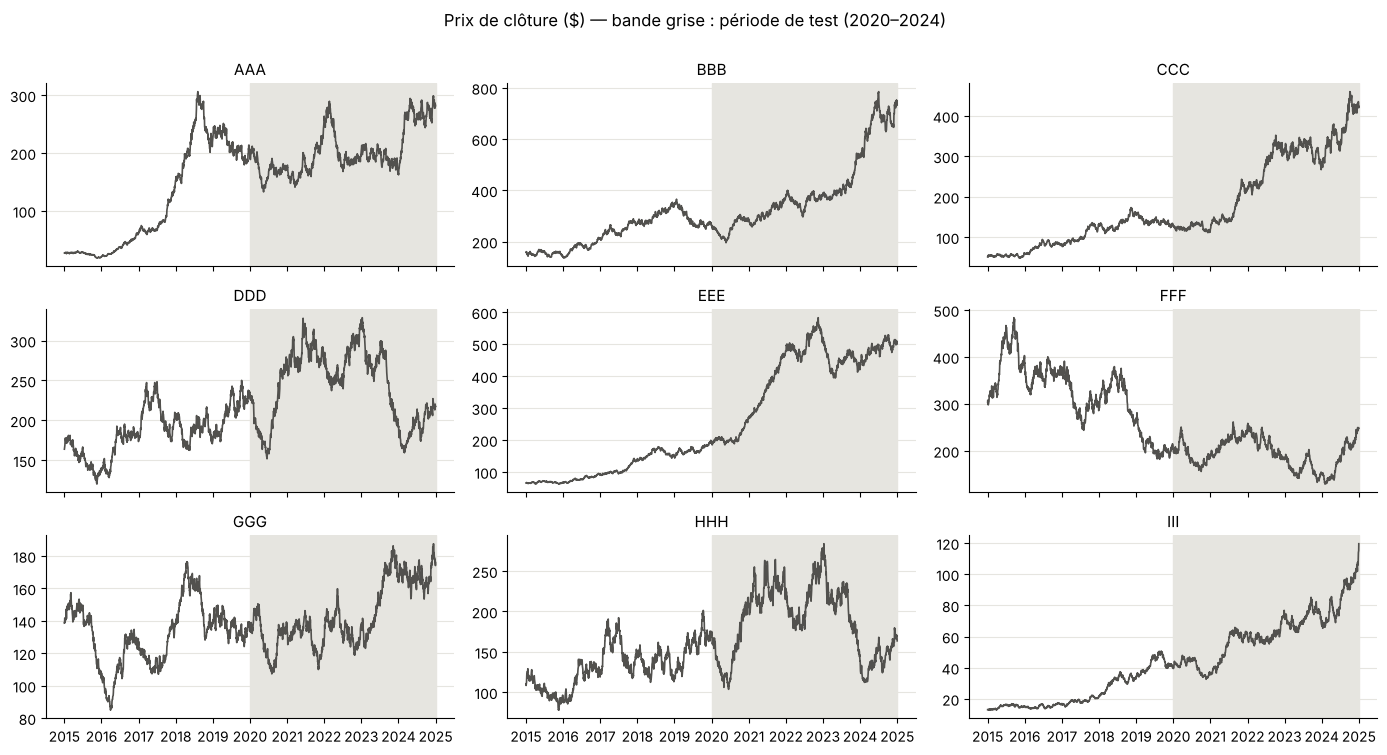

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 7.5), sharex=True)
for ax, t in zip(axes.flat, TICKERS):
    ax.plot(prices.index, prices[t], color=GRAY, linewidth=1.2)
    ax.set_title(t, fontsize=11)
    shade_test(ax, label=False)
    style_ax(ax)
fig.suptitle(r"Prix de clôture (\$) — bande grise : période de test (2020–2024)", y=1.0)
plt.tight_layout(); plt.show()

Les neuf actions ont des trajectoires très différentes. Deux courbes se ressemblent à l'œil : **DDD et HHH** (même creux en 2018, même sommet en 2022, même chute en 2023). Mais deux courbes qui se ressemblent ne sont pas forcément cointégrées : c'est ce que teste la section 3.

### 2.4 Corrélation des rendements (2015–2019)

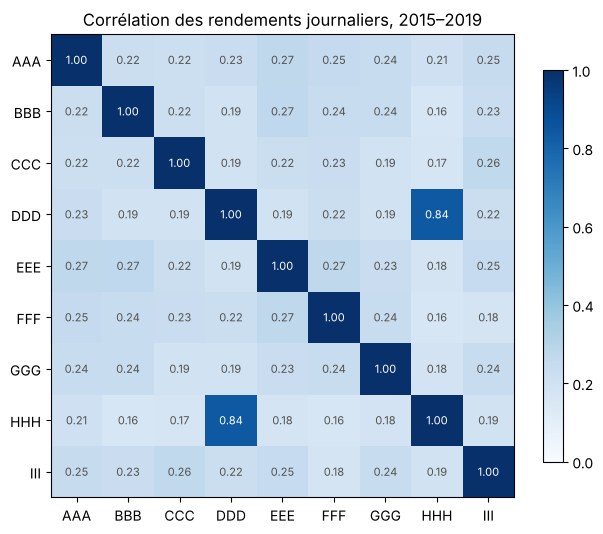

Paire la plus corrélée : DDD et HHH (0.84)
Autres paires          : de 0.16 à 0.27


In [6]:
corr = returns.loc[FORMATION].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(TICKERS)), TICKERS)
ax.set_yticks(range(len(TICKERS)), TICKERS)
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if corr.iloc[i, j] > 0.6 else GRAY)
ax.set_title("Corrélation des rendements journaliers, 2015–2019")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

off_diag = corr.where(~np.eye(len(TICKERS), dtype=bool)).stack()
print(f"Paire la plus corrélée : {' et '.join(off_diag.idxmax())} ({off_diag.max():.2f})")
print(f"Autres paires          : de {off_diag.drop(off_diag.idxmax()).min():.2f} à {off_diag.drop([off_diag.idxmax(), off_diag.idxmax()[::-1]]).max():.2f}")

DDD et HHH ont une corrélation de 0,84 ; toutes les autres paires sont entre 0,16 et 0,27, un niveau typique pour deux actions qui partagent seulement l'influence du marché. DDD et HHH sont vraisemblablement deux entreprises du même secteur.

**Attention : corrélation et cointégration ne sont pas la même chose.** La corrélation mesure si deux actions bougent dans le même sens **le même jour**. La cointégration mesure si leurs **prix** restent liés **à long terme**. Deux actions très corrélées peuvent dériver lentement l'une de l'autre (pas de cointégration), et deux actions peu corrélées au jour le jour peuvent rester liées à long terme. La corrélation donne une piste ; seul un test de cointégration permet de choisir.

### 2.5 Bilan de l'inspection

| Constat | Décision |
|---|---|
| Aucune valeur manquante, aucun doublon, aucun prix aberrant | Aucun nettoyage nécessaire |
| Calendrier de 261 jours par an, jours fériés inclus (données synthétiques) | Annualiser avec 261 jours |
| Pas de saut de prix suspect (fractionnement, erreur) | Prix utilisés tels quels |
| Prix figés rares (arrondi à deux décimales pour III) | Sans conséquence |
| DDD et HHH très corrélées (0,84) | Piste à confirmer par un test de cointégration |

## 3. Choisir la paire (2015–2019 seulement)

On travaille sur le **logarithme** des prix. Ainsi, le spread se lit en pourcentage, et le ratio de couverture devient un ratio en dollars (section 4.1).

### 3.1 Chaque prix est-il une marche aléatoire ?

La cointégration n'a de sens que pour des séries **non stationnaires** : des prix qui n'ont pas de niveau fixe vers lequel revenir. Le test de Dickey-Fuller augmenté (ADF) vérifie ça. Son hypothèse nulle est « la série a une racine unitaire (marche aléatoire) ». Une p-value élevée signifie qu'on ne peut pas la rejeter.

In [7]:
log_prices = np.log(prices)
form = log_prices.loc[FORMATION]

adf_table = pd.DataFrame({
    "p-value ADF : log-prix": [adfuller(form[t])[1] for t in TICKERS],
    "p-value ADF : rendements": [adfuller(form[t].diff().dropna())[1] for t in TICKERS],
}, index=TICKERS)
adf_table.style.format("{:.3f}").set_caption("Test ADF sur 2015–2019 (p < 0,05 : stationnaire)")

,p-value ADF : log-prix,p-value ADF : rendements
AAA,0.845,0.000
BBB,0.672,0.000
CCC,0.555,0.000
DDD,0.528,0.000
EEE,0.945,0.000
FFF,0.871,0.000
GGG,0.498,0.000
HHH,0.336,0.000
III,0.905,0.000


Les neuf log-prix sont **non stationnaires** (p-values de 0,34 à 0,95), et leurs rendements sont stationnaires (p = 0,000). Ce sont donc des séries « intégrées d'ordre 1 », comme la plupart des prix d'actions. On peut tester la cointégration sur toutes les paires.

### 3.2 Test de cointégration sur les 36 paires

**Test d'Engle-Granger** : on régresse un log-prix sur l'autre, puis on vérifie avec un test ADF si le résidu (le spread) est stationnaire. L'hypothèse nulle est « pas de cointégration ». Le résultat dépend légèrement du sens de la régression (A sur B ou B sur A) ; on fait les deux et on garde la **plus grande** des deux p-values, par prudence.

**Le piège des tests multiples.** Avec 36 paires et un seuil de 5 %, on s'attend à environ 36 × 5 % ≈ 2 paires « cointégrées » par pur hasard, même si aucune ne l'est. Pour s'en protéger, on applique la **correction de Bonferroni** : on exige p < 0,05 / 36 ≈ 0,0014.

In [8]:
PAIRS = list(itertools.combinations(TICKERS, 2))
BONFERRONI = 0.05 / len(PAIRS)

rows = []
for a, b in PAIRS:
    p_ab = coint(form[a], form[b])[1]
    p_ba = coint(form[b], form[a])[1]
    rows.append({"Paire": f"{a}–{b}", "p (A sur B)": p_ab, "p (B sur A)": p_ba, "p retenue": max(p_ab, p_ba),
                 "Corrélation des rendements": corr.loc[a, b]})
eg = pd.DataFrame(rows).set_index("Paire").sort_values("p retenue")
eg["Cointégrée à 5 %"] = np.where(eg["p retenue"] < 0.05, "oui", "non")
eg["Cointégrée après Bonferroni"] = np.where(eg["p retenue"] < BONFERRONI, "oui", "non")

print(f"Paires cointégrées au seuil de 5 %             : {(eg['p retenue'] < 0.05).sum()} sur {len(PAIRS)}")
print(f"Paires cointégrées après Bonferroni (p < {BONFERRONI:.4f}) : {(eg['p retenue'] < BONFERRONI).sum()}")
eg.head(8).style.format(fmt_p, subset=["p (A sur B)", "p (B sur A)", "p retenue"]) \
    .format("{:.2f}", subset=["Corrélation des rendements"]).set_caption("Engle-Granger sur 2015–2019 : les 8 meilleures paires")

Paires cointégrées au seuil de 5 %             : 2 sur 36
Paires cointégrées après Bonferroni (p < 0.0014) : 1


,p (A sur B),p (B sur A),p retenue,Corrélation des rendements,Cointégrée à 5 %,Cointégrée après Bonferroni
Paire,,,,,,
DDD–HHH,5e-06,3e-06,5e-06,0.84,oui,oui
BBB–CCC,0.0338,0.0286,0.0338,0.22,oui,non
AAA–CCC,0.1973,0.1220,0.1973,0.22,non,non
AAA–BBB,0.2363,0.1760,0.2363,0.22,non,non
FFF–HHH,0.2651,0.0615,0.2651,0.16,non,non
CCC–HHH,0.3257,0.1447,0.3257,0.17,non,non
FFF–III,0.3407,0.2391,0.3407,0.18,non,non
DDD–FFF,0.1688,0.3491,0.3491,0.22,non,non


- **DDD–HHH est la seule paire cointégrée après correction**, avec une p-value d'environ 5 × 10⁻⁶, des centaines de fois sous le seuil. Le résultat ne dépend pas du sens de la régression.
- **BBB–CCC passe le seuil de 5 % (p ≈ 0,03), mais pas la correction.** C'est exactement le faux positif auquel on s'attend avec 36 tests. Sa corrélation au jour le jour (0,22) n'est pas plus élevée que celle des autres paires : rien n'indique un lien économique particulier. On la garde de côté comme **témoin** : si notre raisonnement est juste, elle ne devrait plus être cointégrée en 2020–2024 (vérifié en 6.2).
- Les autres paires sont loin du seuil.

### 3.3 Confirmation avec le test de Johansen

Le test de Johansen est une deuxième méthode, qui traite les deux prix de façon symétrique (pas de variable « dépendante »). Il teste d'abord « aucune relation de cointégration » (r = 0), puis « au plus une » (r ≤ 1).

In [9]:
jo = coint_johansen(form[["DDD", "HHH"]], det_order=0, k_ar_diff=1)
pd.DataFrame({
    "Statistique de trace": jo.lr1,
    "Valeur critique 95 %": jo.cvt[:, 1],
    "Valeur critique 99 %": jo.cvt[:, 2],
    "Hypothèse rejetée": np.where(jo.lr1 > jo.cvt[:, 2], "oui (99 %)", "non"),
}, index=["r = 0 (aucune relation)", "r ≤ 1 (au plus une)"])

,Statistique de trace,Valeur critique 95 %,Valeur critique 99 %,Hypothèse rejetée
r = 0 (aucune relation),38.99,15.49,19.93,oui (99 %)
r ≤ 1 (au plus une),2.46,3.84,6.63,non


Johansen rejette « aucune relation » à 99 %, mais pas « au plus une relation ». Il y a donc **exactement une relation de cointégration** entre DDD et HHH, ce qui confirme Engle-Granger.

**Choix : la paire DDD–HHH.** Quatre raisons :
1. C'est la seule paire significative après correction pour les 36 tests, et la seule qui le soit selon les deux méthodes.
2. Sa p-value est si petite que le choix ne dépend d'aucun seuil.
3. Elle est aussi de loin la paire la plus corrélée (0,84) : le lien statistique a une contrepartie économique plausible (même secteur).
4. Le spread revient vite vers sa moyenne (demi-vie de 14 jours, section 4.3) : assez de trades possibles pour une stratégie.

## 4. Le spread

### 4.1 Estimer le ratio de couverture

On estime, par moindres carrés sur 2015–2019 :

$$\ln(\text{DDD}_t) = \alpha + \beta \, \ln(\text{HHH}_t) + \varepsilon_t$$

Le **spread** est le résidu $\varepsilon_t = \ln(\text{DDD}_t) - \beta \ln(\text{HHH}_t) - \alpha$. Il mesure, en pourcentage, de combien DDD est au-dessus (ou en dessous) de son niveau « normal » par rapport à HHH.

**Pourquoi le logarithme plutôt que le prix ?** Avec le log, la variation du spread est $r_{\text{DDD}} - \beta \, r_{\text{HHH}}$ (deux rendements). Détenir 1 \$ de DDD et vendre à découvert $\beta$ \$ de HHH reproduit donc exactement le spread, quel que soit le niveau des prix. Avec les prix bruts, le nombre d'actions à détenir dépendrait du niveau des prix.

In [10]:
def fit_spread(y, x, period):
    # Régression de ln(y) sur ln(x) sur `period` ; renvoie (alpha, beta, modèle)
    model = sm.OLS(log_prices.loc[period, y], sm.add_constant(log_prices.loc[period, x])).fit()
    return model.params.iloc[0], model.params.iloc[1], model

ALPHA, BETA, ols = fit_spread("DDD", "HHH", FORMATION)
spread = log_prices["DDD"] - BETA * log_prices["HHH"] - ALPHA       # toute la période, paramètres de 2015–2019
MU, SIGMA = spread.loc[FORMATION].mean(), spread.loc[FORMATION].std()
zscore = (spread - MU) / SIGMA

print(f"alpha = {ALPHA:.4f}   beta = {BETA:.4f}   R² = {ols.rsquared:.3f}")
print(f"Spread sur 2015–2019 : moyenne {MU:.4f}, écart type {SIGMA:.4f} (soit {SIGMA:.1%} d'écart typique entre DDD et sa valeur « normale »)")

alpha = 1.3602   beta = 0.7910   R² = 0.964
Spread sur 2015–2019 : moyenne -0.0000, écart type 0.0310 (soit 3.1% d'écart typique entre DDD et sa valeur « normale »)


- **β = 0,79** : pour chaque dollar de DDD acheté, on vend à découvert 0,79 \$ de HHH. HHH est plus volatile que DDD (36 % contre 25 % par an), donc il en faut moins pour couvrir le même risque.
- **R² = 0,96** : HHH explique presque toute l'évolution de DDD.
- L'écart type du spread est d'environ **3 %**. Un z-score de 2 correspond donc à DDD environ 6 % trop cher (ou trop bon marché) par rapport à HHH.

### 4.2 Évolution du spread

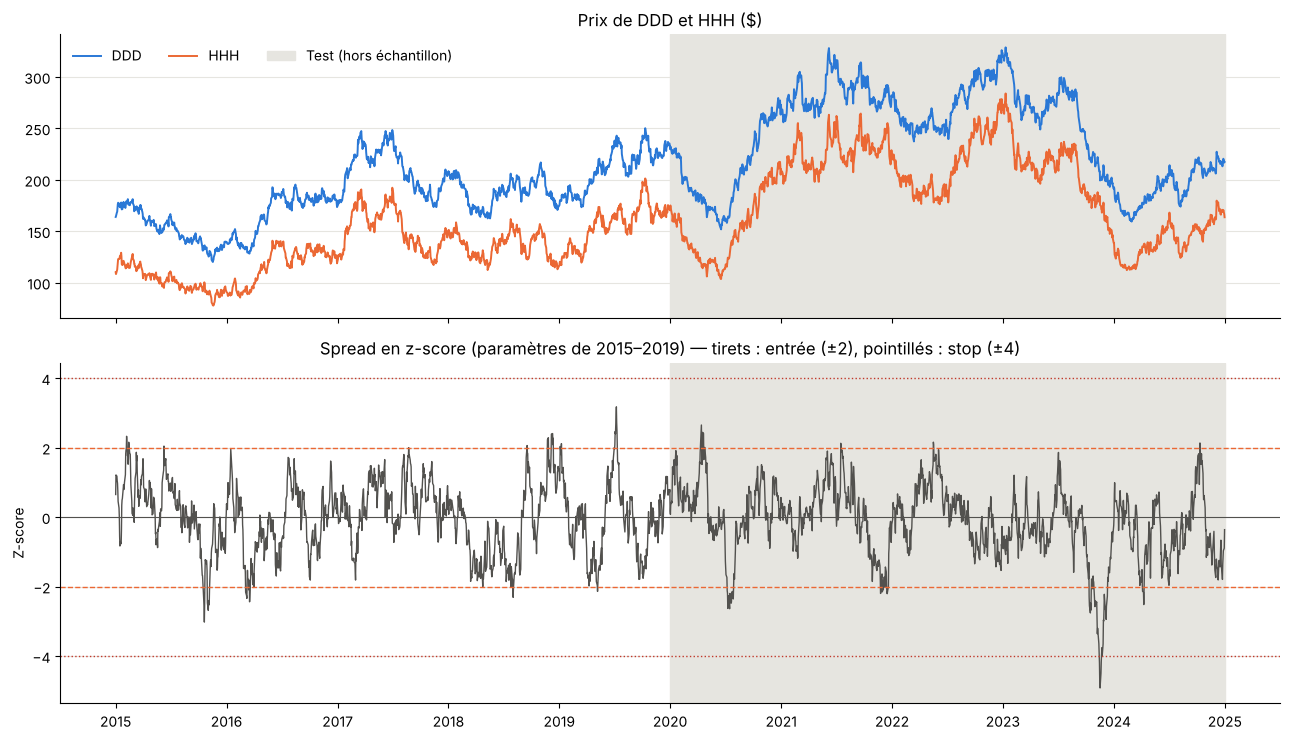

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})

ax = axes[0]
for t in ["DDD", "HHH"]:
    ax.plot(prices.index, prices[t], color=COLORS[t], linewidth=1.4, label=t)
shade_test(ax)
ax.set_title(r"Prix de DDD et HHH (\$)")
ax.legend(frameon=False, ncol=3, loc="upper left")
style_ax(ax)

ax = axes[1]
ax.plot(zscore.index, zscore, color=GRAY, linewidth=1)
for level, style in [(2, "--"), (-2, "--"), (4, ":"), (-4, ":")]:
    ax.axhline(level, color=COLORS["HHH"] if abs(level) == 2 else "#c0392b", linestyle=style, linewidth=1)
ax.axhline(0, color=GRAY, linewidth=0.8)
shade_test(ax, label=False)
ax.set_ylabel("Z-score")
ax.set_title("Spread en z-score (paramètres de 2015–2019) — tirets : entrée (±2), pointillés : stop (±4)")
style_ax(ax)
plt.tight_layout(); plt.show()

- Malgré des prix qui doublent puis chutent, **le spread oscille autour de zéro** pendant les dix ans. C'est ce que veut dire la cointégration.
- Il dépasse ±2 plusieurs fois par an, puis revient. Ce sont les occasions de trading.
- **En 2020–2024 (bande grise), les paramètres de 2019 continuent de fonctionner** : le spread reste centré, sans dérive. Un épisode se démarque : fin 2023, le z-score descend jusqu'à environ −4,9, plus loin que tout ce qu'on avait vu en formation (minimum de −3,0). C'est le test de résistance de la stratégie (section 6.1).

### 4.3 À quelle vitesse le spread revient-il ?

On estime $\Delta \varepsilon_t = c + \lambda \, \varepsilon_{t-1} + u_t$. Si $\lambda < 0$, le spread est tiré vers sa moyenne, et la **demi-vie** vaut $-\ln 2 / \ln(1 + \lambda)$.

Demi-vie du spread (2015–2019) : 13.6 jours de bourse (environ 3 semaines)
Jours où |z| > 2 en formation  : 3.5%
Z-score extrême en formation   : de -3.02 à 3.18


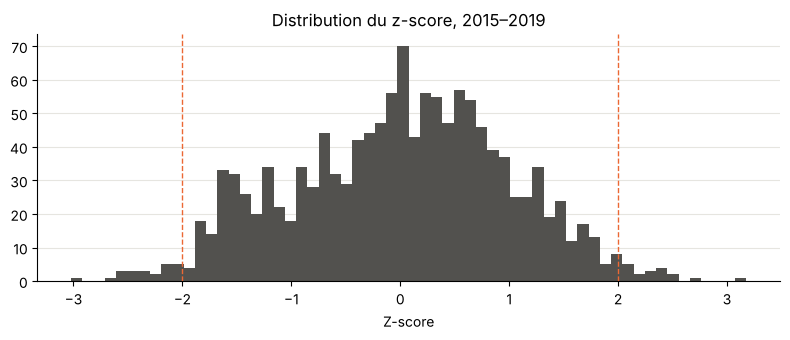

In [12]:
def half_life(s):
    s = s.dropna()
    lam = sm.OLS(s.diff().iloc[1:], sm.add_constant(s.shift(1).iloc[1:])).fit().params.iloc[1]
    return -np.log(2) / np.log(1 + lam)

HALF_LIFE = half_life(spread.loc[FORMATION])
share_beyond_2 = (zscore.loc[FORMATION].abs() > 2).mean()
print(f"Demi-vie du spread (2015–2019) : {HALF_LIFE:.1f} jours de bourse (environ {HALF_LIFE / 5:.0f} semaines)")
print(f"Jours où |z| > 2 en formation  : {share_beyond_2:.1%}")
print(f"Z-score extrême en formation   : de {zscore.loc[FORMATION].min():.2f} à {zscore.loc[FORMATION].max():.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(zscore.loc[FORMATION], bins=60, color=GRAY)
for level in [-2, 2]:
    ax.axvline(level, color=COLORS["HHH"], linestyle="--", linewidth=1)
ax.set_title("Distribution du z-score, 2015–2019")
ax.set_xlabel("Z-score")
style_ax(ax)
plt.tight_layout(); plt.show()

- **Demi-vie d'environ 14 jours de bourse** (3 semaines) : un écart se résorbe en quelques semaines. C'est assez rapide pour trader, et assez lent pour que les coûts de transaction ne mangent pas tout.
- Le z-score dépasse ±2 environ 3,5 % du temps (un peu moins que les 4,6 % d'une loi normale). Il n'est jamais allé au-delà de ±3,2 en formation.

## 5. La stratégie

### 5.1 Règles

Toutes les règles sont fixées **avant** de regarder 2020–2024, à partir de valeurs usuelles et de ce qu'on a observé en formation.

| Élément | Règle | Justification |
|---|---|---|
| **Signal** | Z-score du spread, avec α, β, moyenne et écart type de 2015–2019, **jamais réestimés** | Aucune information du futur ; la stabilité est vérifiée en 6.2 |
| **Entrée** | z ≥ +2 : **vendre le spread** (vendre DDD, acheter HHH). z ≤ −2 : **acheter le spread** (acheter DDD, vendre HHH) | 2 écarts types : environ 3,5 % des jours en formation, donc un écart vraiment inhabituel, mais qui se produit quelques fois par an |
| **Sortie (objectif)** | Le z-score repasse par 0 | Le spread est revenu à sa moyenne : l'écart est entièrement résorbé |
| **Sortie (stop)** | \|z\| ≥ 4 | Jamais vu en formation (maximum 3,2). À 4, la relation est peut-être brisée : on coupe la perte |
| **Après un stop** | Pas de nouvelle entrée tant que \|z\| n'est pas revenu sous 2 | Éviter de reprendre aussitôt une position sur une relation peut-être brisée |
| **Exécution** | Signal calculé à la clôture du jour *t*, exécuté à la clôture du jour *t + 1* | Pas d'anticipation : on ne peut pas trader au prix qui a servi à décider |
| **Positions** | Une seule position à la fois, sur la paire DDD–HHH | Simplicité |

**Taille des positions.** À chaque entrée, on engage **100 % du capital** (exposition brute), réparti selon β pour que la position reproduise le spread :
- jambe DDD : $N = \text{capital} / (1 + \beta)$, soit environ 56 % du capital ;
- jambe HHH : $\beta N$, soit environ 44 % du capital, dans le sens opposé.

Le gain ou la perte vaut alors environ $N \times \Delta\text{spread}$. Un retour du z-score de 2 à 0 (un spread qui bouge d'environ 6 %) rapporte donc environ 0,56 × 6 % ≈ **3,4 % du capital**. Les quantités sont arrondies à l'action entière inférieure. La position est **presque neutre au marché** : l'exposition nette est de (1 − β) N ≈ 12 % du capital, et HHH, plus volatile, compense le risque de marché de DDD.

**Coûts.** 0,05 % de la valeur échangée, par jambe, à l'entrée et à la sortie (commission et écart acheteur-vendeur). Le coût d'emprunt des titres vendus à découvert et l'intérêt sur l'argent non investi sont mis à zéro ; on teste leur effet en 6.4.

In [13]:
def backtest(y, x, z, beta, entry=2.0, exit=0.0, stop=4.0, cost=COST, borrow=0.0, capital=initial_capital):
    '''Simule la stratégie sur la période couverte par `z` (z-score du spread y − beta·x).

    Signal à la clôture t, exécution à la clôture t+1. `beta` est un nombre ou une série
    (valeur lue le jour de l'entrée). Renvoie (capital quotidien, position quotidienne, trades).
    position : +1 = spread acheté (long y, short x), −1 = spread vendu, 0 = aucune.'''
    py, px = prices.loc[z.index, y].values, prices.loc[z.index, x].values
    zz, dates = z.values, z.index
    beta_at = (lambda t: beta) if np.isscalar(beta) else (lambda t: beta.loc[dates[t]])

    eq, pos, target, blocked = capital, 0, 0, False
    sh_y = sh_x = 0.0
    equity, position, trades, trade = np.empty(len(z)), np.zeros(len(z)), [], None

    for t in range(len(z)):
        # 1. Gain ou perte de la journée sur la position détenue (et coût d'emprunt de la jambe vendue)
        if t > 0 and pos != 0:
            eq += sh_y * (py[t] - py[t - 1]) + sh_x * (px[t] - px[t - 1])
            short_value = -min(sh_y * py[t - 1], 0) - min(sh_x * px[t - 1], 0)
            eq -= borrow / DAYS_PER_YEAR * short_value

        # 2. Exécution, à la clôture d'aujourd'hui, de la décision prise hier
        if target != pos:
            if pos != 0:                                   # fermeture
                eq -= cost * (abs(sh_y) * py[t] + abs(sh_x) * px[t])
                trade.update(sortie=dates[t], z_sortie=zz[t], capital_sortie=eq)
                trades.append(trade)
                sh_y = sh_x = 0.0
            if target != 0 and eq > 0:                     # ouverture
                b = beta_at(t)
                n = eq / (1 + b)
                sh_y = target * np.floor(n / py[t])
                sh_x = -target * np.floor(b * n / px[t])
                eq -= cost * (abs(sh_y) * py[t] + abs(sh_x) * px[t])
                trade = dict(entrée=dates[t], sens="achat du spread" if target > 0 else "vente du spread",
                             z_entrée=zz[t], capital_entrée=eq)
            pos = target if eq > 0 else 0

        if eq <= 0:                                        # ruine : on arrête tout
            eq, pos, target = 0.0, 0, 0
        equity[t], position[t] = eq, pos

        # 3. Décision pour demain, à partir du z-score de ce soir
        zt = zz[t]
        if pos == 0:
            if blocked and abs(zt) < entry:
                blocked = False
            if not blocked and eq > 0:
                target = -1 if entry <= zt < stop else (1 if -stop < zt <= -entry else 0)
        else:
            hit_target = (zt >= -exit) if pos > 0 else (zt <= exit)
            hit_stop = (zt <= -stop) if pos > 0 else (zt >= stop)
            if hit_target or hit_stop:
                target = 0
                trade["raison"] = "stop" if hit_stop else "objectif"
                blocked = hit_stop

    if pos != 0:                                           # position encore ouverte à la fin : évaluée au dernier prix
        trade.update(sortie=dates[-1], z_sortie=zz[-1], capital_sortie=eq, raison="fin de période")
        trades.append(trade)

    trades = pd.DataFrame(trades)
    if len(trades):
        trades["P&L ($)"] = trades["capital_sortie"] - trades["capital_entrée"]
        trades["rendement"] = trades["capital_sortie"] / trades["capital_entrée"] - 1
        trades["durée (jours)"] = [len(z.loc[a:b]) - 1 for a, b in zip(trades["entrée"], trades["sortie"])]
    return pd.Series(equity, dates), pd.Series(position, dates), trades

### 5.2 Mesures de performance et de risque

| Mesure | Ce qu'elle dit |
|---|---|
| P&L, rendement total, rendement annualisé | Combien on gagne |
| Volatilité annualisée | Combien le capital fluctue |
| **Ratio de Sharpe** | Rendement par unité de risque (taux sans risque supposé nul). Au-dessus de 1, c'est bon ; une stratégie neutre au marché vise souvent 1 à 2 |
| Ratio de Sortino | Comme le Sharpe, mais ne pénalise que les baisses |
| **Drawdown maximal** et sa durée | La pire perte depuis un sommet, et combien de temps pour la récupérer |
| Ratio de Calmar | Rendement annualisé ÷ drawdown maximal |
| VaR 95 % (1 jour) | Perte journalière dépassée seulement 1 jour sur 20 |
| Taux de réussite, gain et perte moyens | Qualité des trades |
| Temps en position | Part des jours où le capital est investi |
| Corrélation et bêta au marché | Est-ce vraiment neutre au marché ? |

In [14]:
market_ret = prices.pct_change().mean(axis=1)            # portefeuille équipondéré des 9 actions (rebalancé chaque jour)

def market_equity(period):
    r = market_ret.loc[period].copy()
    r.iloc[0] = 0.0
    return initial_capital * (1 + r).cumprod()

def metrics(equity, position=None, trades=None):
    r = equity.pct_change().dropna()
    years = len(r) / DAYS_PER_YEAR
    dd = equity / equity.cummax() - 1
    underwater = (dd < 0).astype(int)
    longest_dd = underwater.groupby((underwater == 0).cumsum()).sum().max()
    cagr = (equity.iloc[-1] / equity.iloc[0]) ** (1 / years) - 1
    downside = r[r < 0].std() * np.sqrt(DAYS_PER_YEAR)
    m = r.loc[market_ret.index.intersection(r.index)]
    mk = market_ret.loc[m.index]
    out = {
        "Capital final ($)": equity.iloc[-1],
        "P&L ($)": equity.iloc[-1] - equity.iloc[0],
        "Rendement total": equity.iloc[-1] / equity.iloc[0] - 1,
        "Rendement annualisé": cagr,
        "Volatilité annualisée": r.std() * np.sqrt(DAYS_PER_YEAR),
        "Ratio de Sharpe": r.mean() / r.std() * np.sqrt(DAYS_PER_YEAR),
        "Ratio de Sortino": r.mean() * DAYS_PER_YEAR / downside,
        "Drawdown maximal": dd.min(),
        "Plus long drawdown (jours)": longest_dd,
        "Ratio de Calmar": cagr / -dd.min(),
        "VaR 95 % (1 jour)": -r.quantile(0.05),
        "Pire jour": r.min(),
        "Corrélation au marché": m.corr(mk),
        "Bêta au marché": m.cov(mk) / mk.var(),
    }
    if position is not None:
        out["Temps en position"] = (position != 0).mean()
    if trades is not None and len(trades):
        out.update({
            "Nombre de trades": len(trades),
            "Taux de réussite": (trades["P&L ($)"] > 0).mean(),
            "Gain moyen (trade gagnant)": trades.loc[trades["P&L ($)"] > 0, "rendement"].mean(),
            "Perte moyenne (trade perdant)": trades.loc[trades["P&L ($)"] <= 0, "rendement"].mean() if (trades["P&L ($)"] <= 0).any() else 0.0,
            "Durée moyenne (jours)": trades["durée (jours)"].mean(),
        })
    return pd.Series(out)

METRIC_ORDER = ["Capital final ($)", "P&L ($)", "Rendement total", "Rendement annualisé", "Volatilité annualisée",
                "Ratio de Sharpe", "Ratio de Sortino", "Drawdown maximal", "Plus long drawdown (jours)", "Ratio de Calmar",
                "VaR 95 % (1 jour)", "Pire jour", "Corrélation au marché", "Bêta au marché", "Temps en position",
                "Nombre de trades", "Taux de réussite", "Gain moyen (trade gagnant)", "Perte moyenne (trade perdant)",
                "Durée moyenne (jours)"]

FMT_PCT = ["Rendement total", "Rendement annualisé", "Volatilité annualisée", "Drawdown maximal", "VaR 95 % (1 jour)",
           "Pire jour", "Temps en position", "Taux de réussite", "Gain moyen (trade gagnant)", "Perte moyenne (trade perdant)"]

def show_metrics(table, caption):
    fmt = {}
    for row in table.index:
        if row in FMT_PCT:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.1%}"
        elif row in ["Capital final ($)", "P&L ($)"]:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:,.0f}"
        elif row in ["Nombre de trades", "Plus long drawdown (jours)"]:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.0f}"
        else:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.2f}"
    table = table.reindex([k for k in METRIC_ORDER if k in table.index])
    out = table.astype(object).copy()
    for row in out.index:
        out.loc[row] = [fmt[row](v) for v in table.loc[row]]
    display(out.style.set_caption(caption))

### 5.3 Résultat sur la période de formation (2015–2019)

C'est un résultat **dans l'échantillon** : la paire et le spread ont été estimés sur ces mêmes données. Il sert à vérifier que la mécanique fonctionne, pas à mesurer la stratégie (c'est le rôle de la section 6).

In [15]:
eq_is, pos_is, trades_is = backtest("DDD", "HHH", zscore.loc[FORMATION], BETA)
m_is = metrics(eq_is, pos_is, trades_is)
show_metrics(m_is.to_frame("Stratégie, 2015–2019"), "Formation (dans l'échantillon)")

,"Stratégie, 2015–2019"
Capital final ($),"140,624"
P&L ($),"40,624"
Rendement total,40.6%
Rendement annualisé,7.1%
Volatilité annualisée,4.5%
Ratio de Sharpe,1.54
Ratio de Sortino,1.33
Drawdown maximal,-4.2%
Plus long drawdown (jours),356
Ratio de Calmar,1.69


Pour vérifier que les seuils choisis (entrée 2, sortie 0) ne sont pas un « coup de chance », on regarde le Sharpe de formation pour d'autres valeurs. Si 2 et 0 étaient un pic isolé, la stratégie serait fragile.

In [16]:
ENTRIES, EXITS = [1.5, 1.75, 2.0, 2.25, 2.5], [-0.5, 0.0, 0.5, 1.0]

def sharpe_grid(period):
    grid = pd.DataFrame(index=[f"entrée {e}" for e in ENTRIES], columns=[f"sortie {x}" for x in EXITS], dtype=float)
    for e in ENTRIES:
        for x in EXITS:
            eq, _, _ = backtest("DDD", "HHH", zscore.loc[period], BETA, entry=e, exit=x)
            grid.loc[f"entrée {e}", f"sortie {x}"] = metrics(eq)["Ratio de Sharpe"]
    return grid

grid_is = sharpe_grid(FORMATION)
grid_is.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=2.5) \
    .set_caption("Ratio de Sharpe en formation selon les seuils (règle retenue : entrée 2, sortie 0)")

,sortie -0.5,sortie 0.0,sortie 0.5,sortie 1.0
entrée 1.5,2.01,2.03,2.46,2.18
entrée 1.75,1.71,1.72,1.93,1.68
entrée 2.0,1.52,1.54,1.68,1.44
entrée 2.25,1.23,1.39,1.27,1.17
entrée 2.5,1.02,1.12,1.03,0.87


- En formation, la stratégie gagne à chaque trade, avec un Sharpe de 1,54. Ce n'est **pas** une mesure fiable : la paire a été choisie *parce que* son spread revenait bien vers sa moyenne sur cette période.
- **Les seuils retenus ne sont pas les meilleurs en formation**, et c'est voulu : un seuil d'entrée de 1,5 ou 1,75 donnait un Sharpe plus élevé. Choisir le maximum du tableau, c'est optimiser sur le bruit. On garde des valeurs usuelles (2 et 0), situées sur un plateau : toutes les combinaisons donnent un Sharpe positif, entre 0,87 et 2,46.
- Les seuils d'entrée élevés (2,5) donnent peu de trades : le z-score atteint rarement ce niveau.

## 6. Résultat hors échantillon (2020–2024)

On applique maintenant, **sans rien changer**, la paire, β, la moyenne et l'écart type du spread, et les seuils fixés avec 2015–2019. On part de 100 000 \$ au 1ᵉʳ janvier 2020.

### 6.1 Profit, risque et trades

In [17]:
eq_oos, pos_oos, trades_oos = backtest("DDD", "HHH", zscore.loc[TEST], BETA)
eq_mkt = market_equity(TEST)

summary = pd.DataFrame({
    "Stratégie, 2015–2019 (formation)": m_is,
    "Stratégie, 2020–2024 (test)": metrics(eq_oos, pos_oos, trades_oos),
    "Marché, 2020–2024": metrics(eq_mkt),
})
m_oos = summary["Stratégie, 2020–2024 (test)"]
show_metrics(summary, "Performance et risque")

,"Stratégie, 2015–2019 (formation)","Stratégie, 2020–2024 (test)","Marché, 2020–2024"
Capital final ($),"140,624","126,597","199,084"
P&L ($),"40,624","26,597","99,084"
Rendement total,40.6%,26.6%,99.1%
Rendement annualisé,7.1%,4.8%,14.8%
Volatilité annualisée,4.5%,3.7%,12.5%
Ratio de Sharpe,1.54,1.28,1.16
Ratio de Sortino,1.33,0.95,2.05
Drawdown maximal,-4.2%,-5.9%,-17.9%
Plus long drawdown (jours),356,259,193
Ratio de Calmar,1.69,0.82,0.83


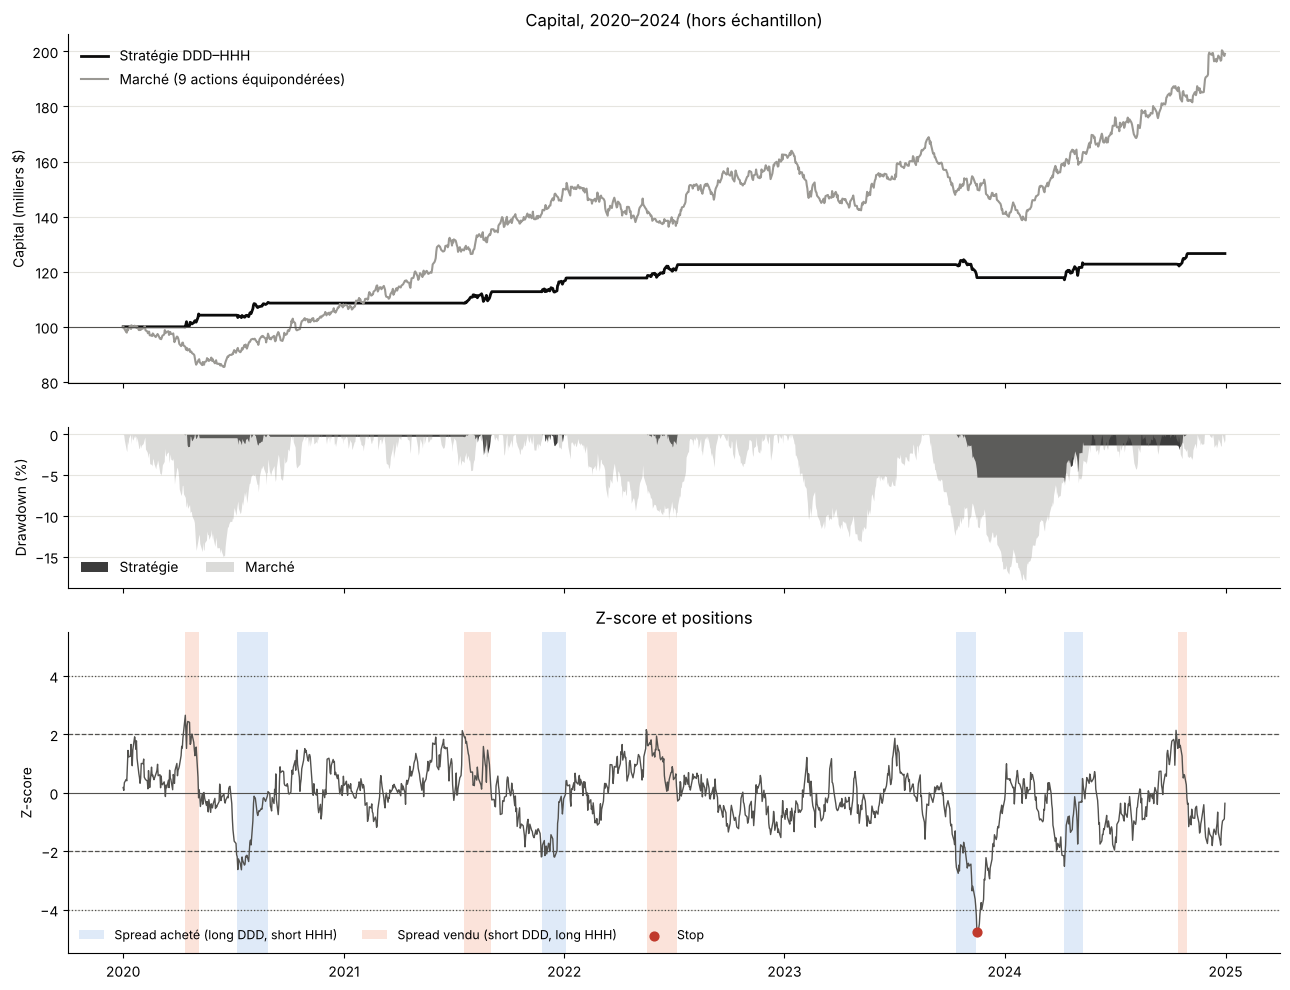

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={"height_ratios": [1.3, 0.6, 1.2]})

ax = axes[0]
ax.plot(eq_oos.index, eq_oos / 1e3, color=COLORS["Stratégie"], linewidth=2, label="Stratégie DDD–HHH")
ax.plot(eq_mkt.index, eq_mkt / 1e3, color=COLORS["Marché"], linewidth=1.5, label="Marché (9 actions équipondérées)")
ax.axhline(initial_capital / 1e3, color=GRAY, linewidth=0.8)
ax.set_ylabel(r"Capital (milliers \$)")
ax.set_title("Capital, 2020–2024 (hors échantillon)")
ax.legend(frameon=False, loc="upper left")
style_ax(ax)

ax = axes[1]
for eq, name in [(eq_oos, "Stratégie"), (eq_mkt, "Marché")]:
    ax.fill_between(eq.index, 100 * (eq / eq.cummax() - 1), 0, color=COLORS[name], alpha=0.35 if name == "Marché" else 0.8, linewidth=0, label=name)
ax.set_ylabel("Drawdown (%)")
ax.legend(frameon=False, loc="lower left", ncol=2)
style_ax(ax)

ax = axes[2]
z_t = zscore.loc[TEST]
ax.plot(z_t.index, z_t, color=GRAY, linewidth=1)
ax.fill_between(z_t.index, -5.5, 5.5, where=pos_oos > 0, color=COLORS["DDD"], alpha=0.15, linewidth=0, label="Spread acheté (long DDD, short HHH)")
ax.fill_between(z_t.index, -5.5, 5.5, where=pos_oos < 0, color=COLORS["HHH"], alpha=0.18, linewidth=0, label="Spread vendu (short DDD, long HHH)")
for level, style in [(2, "--"), (-2, "--"), (4, ":"), (-4, ":")]:
    ax.axhline(level, color=GRAY, linestyle=style, linewidth=0.9)
ax.axhline(0, color=GRAY, linewidth=0.8)
stops = trades_oos[trades_oos["raison"] == "stop"]
ax.scatter(stops["sortie"], stops["z_sortie"], color="#c0392b", zorder=5, s=40, label="Stop")
ax.set_ylim(-5.5, 5.5)
ax.set_ylabel("Z-score")
ax.set_title("Z-score et positions")
ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=9)
style_ax(ax)
plt.tight_layout(); plt.show()

In [19]:
cols = ["entrée", "sortie", "sens", "z_entrée", "z_sortie", "raison", "durée (jours)", "P&L ($)", "rendement"]
view = trades_oos[cols].copy()
view.index = range(1, len(view) + 1)
view["entrée"] = view["entrée"].dt.date
view["sortie"] = view["sortie"].dt.date
view.style.format({"z_entrée": "{:+.2f}", "z_sortie": "{:+.2f}", "P&L ($)": "{:+,.0f}", "rendement": "{:+.2%}"}) \
    .set_caption("Trades, 2020–2024 (z_entrée et z_sortie : z-score le jour de l'exécution, au lendemain du signal)")

,entrée,sortie,sens,z_entrée,z_sortie,raison,durée (jours),P&L ($),rendement
1,2020-04-13,2020-05-06,vente du spread,+2.65,+0.10,objectif,17,"+4,272",+4.27%
2,2020-07-08,2020-08-31,achat du spread,-2.19,-0.03,objectif,38,"+4,442",+4.26%
3,2021-07-19,2021-09-03,vente du spread,+1.93,-0.25,objectif,34,"+4,196",+3.87%
4,2021-11-25,2022-01-05,achat du spread,-2.18,+0.42,objectif,29,"+5,035",+4.47%
5,2022-05-18,2022-07-08,vente du spread,+2.08,-0.28,objectif,37,"+4,900",+4.16%
6,2023-10-13,2023-11-16,achat du spread,-2.55,-4.77,stop,24,"-4,661",-3.80%
7,2024-04-08,2024-05-10,achat du spread,-2.16,+0.26,objectif,24,"+4,955",+4.21%
8,2024-10-14,2024-10-30,vente du spread,+1.52,-0.39,objectif,12,"+3,910",+3.19%


- **Profit de 26 597 \$ en cinq ans** (+26,6 %, soit +4,8 % par an), avec une volatilité de seulement 3,7 %. 7 trades sur 8 sont gagnants, chacun rapportant environ 4 % du capital, comme prévu en 5.1. Le **Sharpe de 1,28** est plus bas qu'en formation (1,54), ce qui est normal hors échantillon, mais il reste bon : la stratégie ne s'est pas effondrée.
- **Le risque est faible et indépendant du marché.** Le pire drawdown est de −5,9 %, contre −17,9 % pour le marché. La corrélation au marché est de 0,03 : le profit ne vient pas de la hausse générale des actions.
- **Le marché a rapporté plus en absolu** (+99,1 %) sur une période très haussière, avec un Sharpe comparable (1,16), mais avec environ trois fois plus de volatilité et un drawdown trois fois plus grand. Les deux ne jouent pas le même rôle : la stratégie est une source de rendement *décorrélée*, qu'on ajoute à un portefeuille, pas un substitut aux actions.
- **Le stop a servi une fois, en octobre–novembre 2023.** Après l'entrée à z ≈ −2,5, le spread a continué de s'écarter jusqu'à environ −4,9, du jamais-vu en formation. La stratégie a coupé la position avec une perte de 3,8 % du capital (le seul trade perdant), puis, selon la règle, n'est pas revenue tant que |z| n'était pas repassé sous 2. Le spread est ensuite revenu vers sa moyenne, sans nous. Avec le recul, le stop a coûté de l'argent (section 6.4), mais on ne pouvait pas savoir sur le moment que la relation tiendrait. C'est le prix d'une assurance contre une rupture de la cointégration.
- **Le capital ne travaille que 16 % du temps.** Le reste du temps, il dort (et ne rapporte rien dans cette simulation). C'est une limite importante, discutée en section 8.

### 6.2 La relation a-t-elle tenu ?

On refait, maintenant seulement, les tests de cointégration sur la période de test, et on réestime β sur 2020–2024 pour le comparer à celui qu'on a utilisé.

In [20]:
test_lp = log_prices.loc[TEST]
rows = []
for a, b in [("DDD", "HHH"), ("BBB", "CCC")]:
    _, beta_form, _ = fit_spread(a, b, FORMATION)
    _, beta_test, _ = fit_spread(a, b, TEST)
    rows.append({
        "Paire": f"{a}–{b}",
        "p-value 2015–2019": max(coint(form[a], form[b])[1], coint(form[b], form[a])[1]),
        "p-value 2020–2024": max(coint(test_lp[a], test_lp[b])[1], coint(test_lp[b], test_lp[a])[1]),
        "β 2015–2019": beta_form,
        "β 2020–2024": beta_test,
    })
ols_level_form = sm.OLS(prices.loc[FORMATION, "DDD"], sm.add_constant(prices.loc[FORMATION, "HHH"])).fit()
ols_level_test = sm.OLS(prices.loc[TEST, "DDD"], sm.add_constant(prices.loc[TEST, "HHH"])).fit()

stability = pd.DataFrame(rows).set_index("Paire")
print(f"Demi-vie DDD–HHH : {HALF_LIFE:.1f} jours en formation, {half_life(spread.loc[TEST]):.1f} jours en test")
print(f"Pour comparaison, β estimé sur les prix bruts (et non les log-prix) : {ols_level_form.params.iloc[1]:.3f} en formation, {ols_level_test.params.iloc[1]:.3f} en test")
stability.style.format(fmt_p, subset=["p-value 2015–2019", "p-value 2020–2024"]).format("{:.3f}", subset=["β 2015–2019", "β 2020–2024"]) \
    .set_caption("Stabilité de la cointégration")

Demi-vie DDD–HHH : 13.6 jours en formation, 15.1 jours en test
Pour comparaison, β estimé sur les prix bruts (et non les log-prix) : 1.101 en formation, 1.030 en test


,p-value 2015–2019,p-value 2020–2024,β 2015–2019,β 2020–2024
Paire,,,,
DDD–HHH,5e-06,2e-05,0.791,0.791
BBB–CCC,0.0338,0.7971,0.726,0.672


- **DDD–HHH est toujours cointégrée en 2020–2024** (p-value encore minuscule), et le β réestimé sur la seule période de test est pratiquement identique à celui de la formation (0,791 dans les deux cas). La demi-vie est aussi stable (environ 14–15 jours). C'est ce qui explique que des paramètres figés en 2019 fonctionnent encore en 2024.
- **BBB–CCC, le faux positif de la section 3.2, ne l'est plus du tout** (p-value élevée). La correction de Bonferroni avait raison de l'écarter.
- Le β estimé sur les prix bruts change davantage (de 1,10 à 1,03) que celui estimé sur les log-prix : travailler en logarithme donne une relation plus stable.

### 6.3 Le profit vient-il de la paire ? Test placebo

Si la stratégie gagnait de l'argent sur n'importe quelle paire, le choix de la paire ne servirait à rien, et le profit viendrait peut-être d'un biais de la simulation. On applique donc **exactement les mêmes règles** (spread estimé sur 2015–2019, mêmes seuils) aux 35 autres paires, sur 2020–2024.

Autres paires : Sharpe médian 0.13, 16 sur 35 perdent de l'argent, 4 ruinent le capital, drawdown médian -26%
DDD–HHH       : Sharpe 1.28 (rang 1 sur 36), drawdown -5.9% (rang 2 sur 36, 1 = le plus petit)


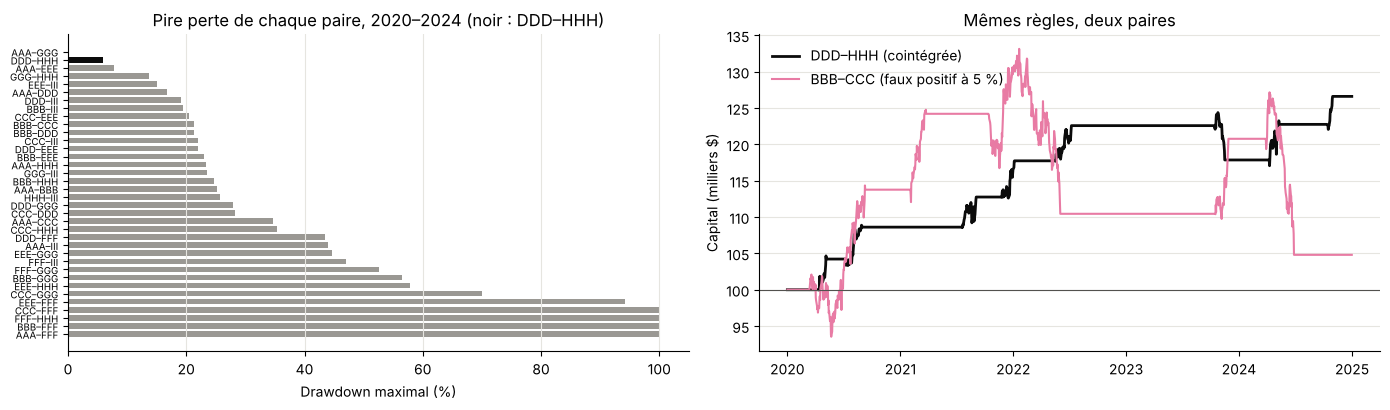

In [21]:
placebo_rows, placebo_eq = [], {}
for a, b in PAIRS:
    al, be, _ = fit_spread(a, b, FORMATION)
    s = log_prices[a] - be * log_prices[b] - al
    z = (s - s.loc[FORMATION].mean()) / s.loc[FORMATION].std()
    eq, pos, tr = backtest(a, b, z.loc[TEST], be)
    placebo_eq[f"{a}–{b}"] = eq
    mm = metrics(eq) if eq.iloc[-1] > 0 and eq.std() > 0 else None     # pas de mesure si ruine ou aucun trade
    placebo_rows.append({
        "Paire": f"{a}–{b}",
        "Rendement total": eq.iloc[-1] / initial_capital - 1,
        "Ratio de Sharpe": mm["Ratio de Sharpe"] if mm is not None else np.nan,
        "Drawdown maximal": (eq / eq.cummax() - 1).min(),
        "Ruine": eq.iloc[-1] <= 0,
    })
placebo = pd.DataFrame(placebo_rows).set_index("Paire")
others = placebo.drop("DDD–HHH")

print(f"Autres paires : Sharpe médian {others['Ratio de Sharpe'].median():.2f}, "
      f"{(others['Rendement total'] < 0).sum()} sur 35 perdent de l'argent, {others['Ruine'].sum()} ruinent le capital, "
      f"drawdown médian {others['Drawdown maximal'].median():.0%}")
print(f"DDD–HHH       : Sharpe {placebo.loc['DDD–HHH', 'Ratio de Sharpe']:.2f} (rang {int(placebo['Ratio de Sharpe'].rank(ascending=False)['DDD–HHH'])} sur 36), "
      f"drawdown {placebo.loc['DDD–HHH', 'Drawdown maximal']:.1%} (rang {int(placebo['Drawdown maximal'].rank(ascending=False)['DDD–HHH'])} sur 36, 1 = le plus petit)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
dd = placebo["Drawdown maximal"].sort_values()
ax.barh(range(len(dd)), -100 * dd.values, color=[COLORS["Stratégie"] if p == "DDD–HHH" else COLORS["Marché"] for p in dd.index], height=0.7)
ax.set_yticks(range(len(dd)), dd.index, fontsize=7)
ax.set_xlabel("Drawdown maximal (%)")
ax.set_title("Pire perte de chaque paire, 2020–2024 (noir : DDD–HHH)")
ax.grid(axis="x", color=SHADE); ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.plot(eq_oos.index, eq_oos / 1e3, color=COLORS["Stratégie"], linewidth=2, label="DDD–HHH (cointégrée)")
ax.plot(placebo_eq["BBB–CCC"].index, placebo_eq["BBB–CCC"] / 1e3, color=COLORS["BBB–CCC"], linewidth=1.5, label="BBB–CCC (faux positif à 5 %)")
ax.axhline(initial_capital / 1e3, color=GRAY, linewidth=0.8)
ax.set_ylabel(r"Capital (milliers \$)")
ax.set_title("Mêmes règles, deux paires")
ax.legend(frameon=False, loc="upper left")
style_ax(ax)
plt.tight_layout(); plt.show()

- **DDD–HHH a le meilleur Sharpe des 36 paires, et le 2ᵉ plus petit drawdown** (seule AAA–GGG fait mieux, parce qu'elle n'a fait aucun trade). Sur les autres, les mêmes règles donnent un Sharpe médian de 0,13, un drawdown médian de −25,7 %, et 4 paires perdent tout le capital : sans cointégration, un spread peut s'écarter indéfiniment et le stop ne suffit pas toujours (les prix sautent au-delà).
- **BBB–CCC**, qui passait le seuil de 5 % sans correction, donne un résultat de +4,8 % en cinq ans (Sharpe 0,15, drawdown de −21,3 %) avec de fortes pertes en cours de route.
- Conclusion : **le profit vient de la cointégration de DDD–HHH**, pas de la mécanique de la stratégie. Le test statistique de la section 3 était la décision la plus importante.

### 6.4 Sensibilité aux choix

On change **un seul** paramètre à la fois et on mesure l'effet sur 2020–2024. Ces résultats sont regardés *après* le test : ils ne servent pas à choisir de meilleurs paramètres, mais à savoir si le résultat tient à un réglage précis.

In [22]:
def run_variant(**kwargs):
    z = kwargs.pop("z", zscore.loc[TEST])
    beta = kwargs.pop("beta", BETA)
    eq, pos, tr = backtest("DDD", "HHH", z, beta, **kwargs)
    m = metrics(eq, pos, tr)
    return m[["Rendement total", "Ratio de Sharpe", "Drawdown maximal", "Nombre de trades"]]

# Variante : spread réestimé chaque 1er janvier avec toutes les données disponibles jusque-là (fenêtre croissante)
z_refit, beta_refit = [], []
for year in range(2020, 2025):
    hist = slice("2015-01-01", f"{year - 1}-12-31")
    al, be, _ = fit_spread("DDD", "HHH", hist)
    s = log_prices["DDD"] - be * log_prices["HHH"] - al
    yr = slice(f"{year}-01-01", f"{year}-12-31")
    z_refit.append((s.loc[yr] - s.loc[hist].mean()) / s.loc[hist].std())
    beta_refit.append(pd.Series(be, index=s.loc[yr].index))
z_refit, beta_refit = pd.concat(z_refit), pd.concat(beta_refit)

variants = {
    "Stratégie retenue": {},
    "Coûts : 0": dict(cost=0.0),
    "Coûts : 0,10 % par jambe": dict(cost=0.0010),
    "Coûts : 0,25 % par jambe": dict(cost=0.0025),
    "Coût d'emprunt : 1 % par an": dict(borrow=0.01),
    "Coût d'emprunt : 3 % par an": dict(borrow=0.03),
    "Sans stop": dict(stop=np.inf),
    "Stop à 3,5": dict(stop=3.5),
    "Stop à 5": dict(stop=5.0),
    "Entrée à 1,5": dict(entry=1.5),
    "Entrée à 2,5": dict(entry=2.5),
    "Sortie à ±0,5": dict(exit=0.5),
    "β et z réestimés chaque année": dict(z=z_refit, beta=beta_refit),
}
sens = pd.DataFrame({name: run_variant(**kw) for name, kw in variants.items()}).T
sens.style.format({"Rendement total": "{:+.1%}", "Ratio de Sharpe": "{:.2f}", "Drawdown maximal": "{:.1%}", "Nombre de trades": "{:.0f}"}) \
    .set_caption("Sensibilité, 2020–2024 (un changement à la fois)")

,Rendement total,Ratio de Sharpe,Drawdown maximal,Nombre de trades
Stratégie retenue,+26.6%,1.28,-5.9%,8
Coûts : 0,+27.6%,1.33,-5.8%,8
"Coûts : 0,10 % par jambe",+25.6%,1.24,-6.0%,8
"Coûts : 0,25 % par jambe",+22.7%,1.10,-6.3%,8
Coût d'emprunt : 1 % par an,+26.1%,1.26,-5.9%,8
Coût d'emprunt : 3 % par an,+25.1%,1.22,-6.0%,8
Sans stop,+37.1%,1.63,-5.3%,8
"Stop à 3,5",+28.6%,1.38,-4.4%,8
Stop à 5,+37.1%,1.63,-5.3%,8
"Entrée à 1,5",+44.6%,1.35,-5.8%,17


In [23]:
grid_oos = sharpe_grid(TEST)
grid_oos.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=2.5) \
    .set_caption("Ratio de Sharpe hors échantillon selon les seuils (règle retenue : entrée 2, sortie 0)")

,sortie -0.5,sortie 0.0,sortie 0.5,sortie 1.0
entrée 1.5,1.22,1.35,1.37,1.49
entrée 1.75,1.20,1.42,1.30,1.38
entrée 2.0,1.22,1.28,1.29,1.06
entrée 2.25,0.85,0.87,0.77,0.69
entrée 2.5,0.88,0.90,0.81,0.73


- **Le résultat ne tient pas à un réglage précis.** Toutes les combinaisons de seuils donnent un Sharpe positif hors échantillon (de 0,69 à 1,49). Les seuils retenus (1,28) ne sont ni les meilleurs ni les pires. Les seuils d'entrée élevés (2,25 et 2,5) font moins bien, surtout parce qu'ils donnent moins de trades. Un seuil plus bas (1,5) aurait donné plus de trades et plus de profit (+44,6 %), avec un Sharpe semblable.
- **Les coûts comptent peu**, parce qu'il y a peu de trades et que chacun vise un mouvement d'environ 6 % du spread. Même à 0,25 % par jambe (cinq fois l'hypothèse de base), la stratégie reste rentable. Le coût d'emprunt a aussi peu d'effet, puisqu'on n'est en position qu'environ 16 % du temps.
- **Le stop a coûté de l'argent sur cette période** : sans stop (ou avec un stop à 5, jamais atteint), le trade de fin 2023 aurait fini par revenir, et le rendement passe à +37,1 %. Un stop plus serré (3,5) fait aussi un peu mieux que 4, parce qu'il coupe la perte plus tôt. Ces écarts tiennent à **un seul épisode** : on ne peut pas en tirer de règle. Sur les paires non cointégrées (section 6.3), c'est le scénario inverse qui se produit. On garde le stop.
- **Réestimer β chaque année ne change presque rien**, ce qui confirme que la relation est stable : figer les paramètres en 2019 n'était pas un handicap.

## 7. Hypothèses et leur effet sur les résultats

| # | Hypothèse | Pourquoi on y croit | Effet si elle est fausse |
|---|---|---|---|
| 1 | La relation DDD–HHH estimée en 2015–2019 reste valide ensuite | Cointégration toujours significative en 2020–2024 ; β identique (6.2) ; réestimer chaque année ne change rien (6.4) | Si la relation se brise, le spread ne revient plus. Le stop à ±4 limite la perte à environ 4 % du capital par trade |
| 2 | On peut trader au prix de clôture du lendemain du signal | Hypothèse courante pour des données journalières | Le prix réel d'exécution diffère légèrement : c'est l'équivalent d'un coût supplémentaire (testé jusqu'à 0,25 %) |
| 3 | Coûts de transaction de 0,05 % par jambe | Ordre de grandeur pour des actions liquides | Faible : rentable même à 0,25 % (6.4) |
| 4 | Vente à découvert toujours possible, sans coût d'emprunt | Hypothèse simplificatrice | Faible : 3 % par an d'emprunt retire peu (6.4). Mais si HHH ou DDD devenait impossible à emprunter, la stratégie serait bloquée |
| 5 | Pas d'intérêt sur l'argent non investi ni sur le produit de la vente à découvert | Choix prudent | Le résultat est **sous-estimé** : le capital dort plus de 80 % du temps et rapporterait le taux sans risque |
| 6 | Le capital couvre 100 % de l'exposition brute (pas de levier) | Prudence | Le rendement est proportionnel au levier. À 2× (permis par les règles de marge usuelles), rendement et drawdown doublent environ ; le Sharpe ne change pas |
| 7 | Les prix sont fiables et sans dividendes ni fractionnements à ajuster | Inspection (section 2) : aucun saut suspect | Un dividende non inclus fausserait légèrement le spread ; sans effet visible ici |

## 8. Limites

- **Peu de trades.** 8 trades en cinq ans hors échantillon, 18 en dix ans. C'est assez pour voir que la stratégie fonctionne, mais trop peu pour estimer précisément son rendement : un ou deux trades perdants de plus changeraient nettement le résultat. L'erreur type d'un ratio de Sharpe estimé sur cinq ans est d'environ 0,6 : le Sharpe de 1,28 est donc (tout juste) significativement positif, mais sa vraie valeur pourrait être n'importe où entre environ 0,1 et 2,5.
- **Les données sont vraisemblablement synthétiques** (calendrier sans jours fériés, une seule paire nettement cointégrée, relation parfaitement stable sur dix ans). Sur de vraies actions, les relations de cointégration se brisent souvent : fusion, changement de stratégie d'une des deux entreprises, choc sectoriel. Une stabilité aussi parfaite serait rare.
- **Le capital est mal utilisé.** Il n'est investi qu'environ 16 % du temps. En pratique, on combinerait plusieurs paires (dans un univers plus grand que neuf actions) pour que le capital travaille en continu, ou on utiliserait un levier modéré.
- **Le stop est un compromis.** Il protège contre une rupture de la relation, mais il a coûté de l'argent ici. Un épisode comme celui de fin 2023 montre que le spread peut aller plus loin que tout ce qu'on a vu en formation ; un épisode plus grave pourrait dépasser le stop d'un coup (saut de prix), et la perte serait plus grande que prévu.
- **Aucune information sur les entreprises.** On ne sait pas pourquoi DDD et HHH sont liées. Dans la réalité, on vérifierait qu'il y a une raison économique durable (même secteur, mêmes clients, mêmes coûts), ce qui donne confiance que le lien survivra.
- **Le choix entre 36 paires reste une forme de recherche** : même avec Bonferroni, une partie de la qualité observée en formation vient de la sélection. C'est pourquoi seule la période de test compte pour juger la stratégie.

## 9. Conclusion

Sur les 36 paires possibles, **DDD et HHH est la seule paire réellement cointégrée** : elle passe deux tests différents, même après correction pour les tests multiples, alors que la deuxième candidate (BBB–CCC) est un faux positif qui disparaît ensuite. Le spread $\ln(\text{DDD}) - 0{,}79 \ln(\text{HHH})$ revient vers sa moyenne avec une demi-vie d'environ trois semaines.

Une stratégie simple (entrer à ±2 écarts types, sortir au retour à la moyenne, couper à ±4), fixée avec 2015–2019 et appliquée sans changement à 2020–2024, **transforme 100 000 \$ en 126 597 \$**, avec un Sharpe de 1,28, un drawdown maximal de −5,9 % et une corrélation au marché presque nulle. Le résultat résiste aux coûts, aux seuils et à la réestimation des paramètres, et les mêmes règles échouent sur les paires non cointégrées : le profit vient bien de la relation entre DDD et HHH.

La principale réserve est le petit nombre de trades et le caractère vraisemblablement synthétique des données. Sur de vraies actions, il faudrait surveiller en continu que la relation tient, et diversifier sur plusieurs paires.

In [24]:
final = summary.loc[["Capital final ($)", "P&L ($)", "Rendement total", "Rendement annualisé", "Volatilité annualisée",
                     "Ratio de Sharpe", "Drawdown maximal", "Corrélation au marché", "Nombre de trades", "Taux de réussite"]]
show_metrics(final, "Résultat final — paire DDD–HHH, 100 000 $ de départ")

,"Stratégie, 2015–2019 (formation)","Stratégie, 2020–2024 (test)","Marché, 2020–2024"
Capital final ($),"140,624","126,597","199,084"
P&L ($),"40,624","26,597","99,084"
Rendement total,40.6%,26.6%,99.1%
Rendement annualisé,7.1%,4.8%,14.8%
Volatilité annualisée,4.5%,3.7%,12.5%
Ratio de Sharpe,1.54,1.28,1.16
Drawdown maximal,-4.2%,-5.9%,-17.9%
Corrélation au marché,-0.02,0.03,1.00
Nombre de trades,10,8,—
Taux de réussite,100.0%,87.5%,—
